# Week 7 · Day 1 — Designing an A/B test: starter + HW 7.1

Nur Finance · Kamola's new loan-offer screen. Part 0 is a walk-through (run and read): sample size, hashing, peeking.
Then **five functions** (TODO), each followed by an **assert cell**; a red cell is a function you have not written yet.
Part 2 runs your functions on the **A/A** files — those numbers go into HW 7.1's design document.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize, proportion_confint
from statsmodels.stats.power import NormalIndPower, zt_ind_solve_power
from statsmodels.stats.multitest import multipletests
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA = Path("../..")           # this notebook lives in data/python/week7/, so "../.." is the data/ folder
AB = DATA / "ab"
rng = np.random.default_rng(2026)   # one seeded generator: the same "random" numbers on every run


def check(value, fingerprints, dp=0):
    """Right or wrong without showing the answer: the rounded value's fingerprint must be one of the expected ones."""
    fp = hashlib.sha256(f"nur-w7:{round(float(value), dp):.{dp}f}".encode()).hexdigest()[:12]
    assert fp in fingerprints, "not yet: this result is not the expected one — check your function and run again"

## 0a. Sample size — how many users per arm?
Baseline conversion (offer view → contract signed within 7 days) is about **8.0 %**. Kamola wants to see **+0.9 points** (8.0 → 8.9 %,
+11 % relative). α = 5 % two-sided, power 80 % — week 6's tools, unchanged.

In [2]:
p1, p2 = 0.080, 0.089
h = proportion_effectsize(p2, p1)                                   # Cohen's h
n_arm = zt_ind_solve_power(effect_size=h, alpha=0.05, power=0.80)
za, zb = stats.norm.ppf(0.975), stats.norm.ppf(0.80)
pbar = (p1 + p2) / 2
n_classic = (za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2)))**2 / (p2 - p1)**2
print(f"h = {h:.5f} · n per arm = {n_arm:.1f} (Cohen's h) · {n_classic:.1f} (classic formula)")
traffic = 1000   # app users opening the offer screen per day (the A/A run's level)
print(f"total {2 * np.ceil(n_arm):.0f} users → {2 * np.ceil(n_arm) / traffic:.1f} days at {traffic} a day")

h = 0.03237 · n per arm = 14982.2 (Cohen's h) · 14991.1 (classic formula)
total 29966 users → 30.0 days at 1000 a day


In [3]:
# The same question for other effect sizes: what does each MDE cost in days?
rows = []
for mde in (0.004, 0.005, 0.008, 0.009, 0.012, 0.016):
    n = int(np.ceil(zt_ind_solve_power(effect_size=proportion_effectsize(p1 + mde, p1), alpha=0.05, power=0.80)))
    rows.append([f"+{mde*100:.1f} pt", f"{mde / p1:.1%}", n, round(2 * n / traffic, 1)])
pd.DataFrame(rows, columns=["MDE (absolute)", "relative", "n per arm", "days at 1 000/day"])

,MDE (absolute),relative,n per arm,days at 1 000/day
0,+0.4 pt,5.0%,73844,147.7
1,+0.5 pt,6.2%,47519,95.0
2,+0.8 pt,10.0%,18863,37.7
3,+0.9 pt,11.2%,14983,30.0
4,+1.2 pt,15.0%,8559,17.1
5,+1.6 pt,20.0%,4912,9.8


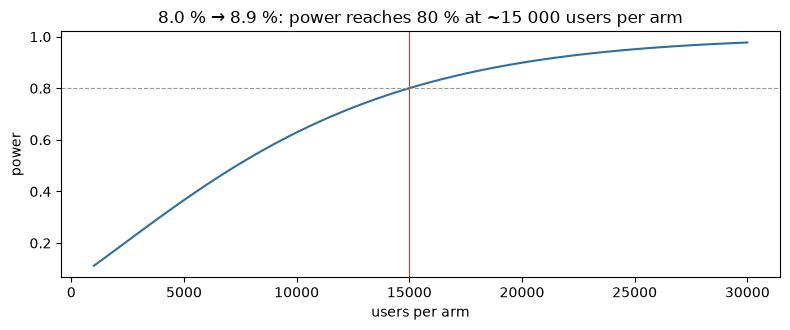

In [4]:
# Power curve: the chance of detecting a true +0.9 pt lift, by users per arm
ns = np.arange(1000, 30001, 500)
pw = [NormalIndPower().power(h, nobs1=n, alpha=0.05) for n in ns]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ns, pw, color="#2f6f9f")
ax.axhline(0.8, color="#999", lw=0.8, ls="--"); ax.axvline(np.ceil(n_arm), color="#c0392b", lw=0.8)
ax.set_xlabel("users per arm"); ax.set_ylabel("power"); ax.set_title("8.0 % → 8.9 %: power reaches 80 % at ~15 000 users per arm")
plt.tight_layout(); plt.show()

## 0b. Randomising by hashing the user id
A hash turns `salt + user_id` into a huge number that looks random but is **always the same** for the same input. Even → A,
odd → B. The salt (the experiment's name) makes each experiment's split independent of the last one.

In [5]:
aa = pd.read_csv(AB / "aa_users.csv", parse_dates=["assigned_at"])
aa_events = pd.read_csv(AB / "aa_events.csv", parse_dates=["event_time"])
demo = aa[["user_id", "variant"]].head(5).copy()
demo["sha256 (first 12 hex)"] = [hashlib.sha256(f"offer_screen_aa_2026_07{u}".encode()).hexdigest()[:12] for u in demo.user_id]
demo["as integer, mod 2"] = [int(hashlib.sha256(f"offer_screen_aa_2026_07{u}".encode()).hexdigest(), 16) % 2 for u in demo.user_id]
demo["other salt, mod 2"] = [int(hashlib.sha256(f"another_test{u}".encode()).hexdigest(), 16) % 2 for u in demo.user_id]
demo

,user_id,variant,sha256 (first 12 hex),"as integer, mod 2","other salt, mod 2"
0,925601,B,58f3d270aad9,1,0
1,665666,A,ef6384316831,0,0
2,652995,A,487ef4139731,0,1
3,774155,B,1181da91cddc,1,0
4,376261,A,31f048fb41e2,0,0


In [6]:
# An uneven split (e.g. 10 % to B for a risky change): normalise the hash to [0, 1) and cut it
def bucket_share(user_id, salt):
    return (int(hashlib.sha256(f"{salt}{user_id}".encode()).hexdigest(), 16) % 10_000) / 10_000
share = aa["user_id"].map(lambda u: bucket_share(u, "risky_change_v1"))
print("share of A/A users that a 90/10 split would send to B:", f"{(share >= 0.90).mean():.2%}")

share of A/A users that a 90/10 split would send to B: 9.75%


## 0c. Peeking — why "stop when it is significant" breaks the 5 %
5 000 simulated **A/A** experiments: both arms convert at 8 %, 500 users per arm per day, 28 days. Test once at the end,
or test every day and stop at the first p < 0.05.

In [7]:
R, days, per_day, p0 = 5000, 28, 500, 0.08
g = np.random.default_rng(2026)
a = g.binomial(per_day, p0, size=(R, days)).cumsum(axis=1)
b = g.binomial(per_day, p0, size=(R, days)).cumsum(axis=1)
n_cum = per_day * np.arange(1, days + 1)
pooled = (a + b) / (2 * n_cum)
z = (b / n_cum - a / n_cum) / np.sqrt(pooled * (1 - pooled) * 2 / n_cum)
p = 2 * stats.norm.sf(np.abs(z))
fixed = np.mean(p[:, -1] < 0.05)
daily = np.mean((p < 0.05).any(axis=1))
weekly = np.mean((p[:, [6, 13, 20, 27]] < 0.05).any(axis=1))
pocock = np.mean((p[:, [6, 13, 20, 27]] < 0.0182).any(axis=1))
print(f"false positives — one test at day 28: {fixed:.1%} · a look every day: {daily:.1%} · a look every week: {weekly:.1%}")
print(f"weekly looks with a stricter threshold (Pocock, p < 0.0182 at each of 4 looks): {pocock:.1%}")

false positives — one test at day 28: 4.9% · a look every day: 27.2% · a look every week: 12.4%
weekly looks with a stricter threshold (Pocock, p < 0.0182 at each of 4 looks): 4.8%


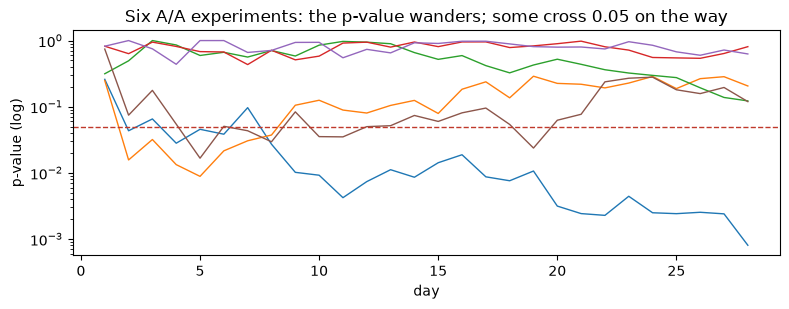

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i in range(6):
    ax.plot(np.arange(1, days + 1), p[i], lw=1)
ax.axhline(0.05, color="#c0392b", lw=1, ls="--")
ax.set_yscale("log"); ax.set_xlabel("day"); ax.set_ylabel("p-value (log)")
ax.set_title("Six A/A experiments: the p-value wanders; some cross 0.05 on the way")
plt.tight_layout(); plt.show()

## 1. `n_per_arm(p1, p2, alpha=0.05, power=0.80)` — users per arm for a two-sided test of two proportions (round **up**)

In [9]:
def n_per_arm(p1, p2, alpha=0.05, power=0.80):
    """Users needed in EACH arm to detect p1 -> p2 (Cohen's h + zt_ind_solve_power, or the classic formula), as an int."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [10]:
check(n_per_arm(0.080, 0.089), ['01a99effb82e', '032ba6a13328', '12b2a19c8a26', '297c4b09b0a9', '445341c43b4d', '47a8fe3f3c3e', '47acba7a2199', '5952b77821b2', '5cf7d34ce63a', '9f706d60bb1f', 'a02b577e31f8', 'a0c054892c38', 'a60784d138b9', 'a89cf026690d', 'ab177ec91a26', 'af2727687cd6', 'c1d3efbff2c9', 'd4b1543c29f4', 'dd5ae46dd1c1', 'f32316dcd30d', 'f8505b97704b'])        # Cohen's h and the classic formula both pass
check(n_per_arm(0.080, 0.096), ['00a002bc4102', '0d2c58487c58', '193641168152', '20e97c1cbb0d', '33d196011a85', '3790a7b2019c', '4cb9530e4aa7', '5039cc35f976', '514f95d6908c', '524e47112216', '60c3cb4a3cfb', '69bfbb463212', '793afd8c9822', '8de34e2c2656', '9beb82ab50d5', '9fa53df6fbd0', 'a3f4665eaaeb', 'a6b04dea627e', 'a84240b7332b', 'b5943762f8c0', 'fe5e3f5699c7'])
check(n_per_arm(0.080, 0.089, power=0.90), ['0f6cbf7a229d', '11fc3bd0a21d', '14093df0cf2e', '1b8266c56b62', '1d478b8b2992', '3675dca74c46', '43ada89baaf3', '5adbb1731779', '5e8437182580', '66f8246bc819', '69212e05eca4', '6bc51ecc26b5', '70ca2c9e3361', '76dc73d1dcb6', '797ad1317bde', '7aa2f985d53e', '7ec74ac69259', '85295a1a8e4b', '883ae0da2fa4', '923afd5ae104', '950067b27d03', 'a06570556d96', 'a3d6a03da1de', 'ad9ac720f7fd', 'af8efc49ed0a', 'b7b87958ce15', 'c66682c025be', 'ca36690a62fa', 'cd851a774a66', 'e0575d3d690b', 'e7833d91d682'])
assert isinstance(n_per_arm(0.08, 0.089), (int, np.integer))
print("n_per_arm OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 2. `hash_variant(user_id, salt)` — 'A' if sha256(salt + str(user_id)) as an integer is even, else 'B'

In [11]:
def hash_variant(user_id, salt):
    """Deterministic 50/50 assignment by hashing."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [12]:
assert hash_variant(496069, "offer_screen_aa_2026_07") == aa.loc[aa.user_id == 496069, "variant"].item()
assert (aa["user_id"].map(lambda u: hash_variant(u, "offer_screen_aa_2026_07")) == aa["variant"]).all()
print("hash_variant OK — every A/A row matches the logged variant")

NotImplementedError: TODO: write me, then run the assert cell below

## 3. `srm_pvalue(n_a, n_b, expected_share_b=0.5)` — chi-square goodness-of-fit p-value for the split

In [13]:
def srm_pvalue(n_a, n_b, expected_share_b=0.5):
    """Sample ratio mismatch check: is n_a : n_b consistent with the planned split? Return the p-value."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [14]:
check(srm_pvalue(14200, 13800), ['151c19e93674', '1ba9e7f94e07', '285e8d71ad3e', '337ffc17a42b', '61b35d0ceb1a', '64024ceacf7c', '73d45223d4e9', 'a7cc12976036', 'afd6740fb64a', 'ba22b4db5851', 'bbdbfe1864d1', 'c53b87ba40dc', 'd29a41ed1cb6', 'd2d64bf4fd93', 'd726f4e08d3f', 'd72e56f0b965', 'd82c32f3c06d', 'deb9f8484b96', 'e90dcae76405', 'f4f21204c755', 'f6d3d4748f19'], 4)
check(srm_pvalue(14050, 13950), ['0ca9878a4434', '0e3146a53559', '1408608a007d', '15e19ab8080a', '2f1bb96186d4', '3b3ba0665ed2', '41a31a47fd94', '4482da908f07', '540977b0f4f2', '602490c8b1cf', '60ae10361402', '757328c761d4', '8ccd8590c24d', '90ac25ef35dc', 'c1532eabdc37', 'd2d888879e4b', 'eb9856244156', 'f4072aca1760', 'f8097abbfbdb', 'f990432a5093', 'fa038e08d03c'], 4)
check(srm_pvalue(9000, 1000, expected_share_b=0.1), ['ce67dde90b19'], 6)
print("srm_pvalue OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 4. `conversion_table(users, events, window_days=7)` — per variant: users, converters (signed within the window), rate

In [15]:
def conversion_table(users, events, window_days=7):
    """DataFrame indexed by variant with columns users, converters, rate. A user converts if their FIRST
    contract_signed event is within window_days * 24 h of assigned_at."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [16]:
t = conversion_table(aa, aa_events)
check(t.loc["A", "users"], ['2cfb244f0be3']); check(t.loc["A", "converters"], ['9c18b8db176b'])
check(t.loc["B", "users"], ['9acc82926361']); check(t.loc["B", "converters"], ['ceae1a0ecaed'])
print(t)

NotImplementedError: TODO: write me, then run the assert cell below

## 5. `two_prop_test(k_a, n_a, k_b, n_b)` — difference B − A, its 95 % Newcombe CI, and the two-sided z-test p-value

In [17]:
def two_prop_test(k_a, n_a, k_b, n_b):
    """Return a dict: rate_a, rate_b, diff (B - A), ci_low, ci_high, z, p."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [18]:
ka, na, kb, nb_ = (int(t.loc[v, c]) for v in ("A", "B") for c in ("converters", "users"))   # your table from step 4
r = two_prop_test(ka, na, kb, nb_)
assert abs(r["diff"] - (kb / nb_ - ka / na)) < 1e-12
check(r["p"], ['011dd7adc990', '0b228658e441', '36d8d8d7e90f', '3aadc5bb4807', '3ed62d9a8fb4', '7185735667cd', '73c5c3ad51c1', '759755556e83', '779ed9ae8ce3', '8085dcd240ad', '878b291998ff', '9146549aa6da', '9557340aaa63', '988309842295', '995854263d0f', '9e2750da4f76', 'a7c69d4b6385', 'ae8c6b733134', 'c1b6ca976700', 'e5464cb80aa1', 'e78401a40ad4'], 4); assert r["ci_low"] < 0 < r["ci_high"]
print({k: round(v, 5) for k, v in r.items()})

NameError: name 't' is not defined

## 6. HW 7.1 — the A/A check (paste these numbers into your design document)
Run once your five functions pass. The A/A run should look boring: a split close to 50/50, no difference.

In [19]:
counts = aa["variant"].value_counts().reindex(["A", "B"])
t = conversion_table(aa, aa_events)
r = two_prop_test(t.loc["A", "converters"], t.loc["A", "users"], t.loc["B", "converters"], t.loc["B", "users"])
print(f"A/A split {counts['A']} / {counts['B']} · SRM p = {srm_pvalue(counts['A'], counts['B']):.3f}")
print(f"conversion A {r['rate_a']:.2%} · B {r['rate_b']:.2%} · difference {r['diff']*100:+.2f} pt "
      f"(95 % CI {r['ci_low']*100:+.2f} to {r['ci_high']*100:+.2f}) · p = {r['p']:.3f}")

NotImplementedError: TODO: write me, then run the assert cell below

In [20]:
# Bonus: does the TEST behave on this data? 1 000 random re-splits of the A/A users -> about 5 % "significant"
s_ = aa_events[aa_events.event_name == "contract_signed"].groupby("user_id").event_time.min()
y = ((aa.user_id.map(s_) - aa.assigned_at).dt.total_seconds() <= 7 * 86400).astype(int).to_numpy()
g = np.random.default_rng(2026)
ps = []
for _ in range(1000):
    m = g.random(len(y)) < 0.5
    ps.append(proportions_ztest([y[m].sum(), y[~m].sum()], [m.sum(), (~m).sum()])[1])
ps = np.array(ps)
print(f"share of re-splits with p < 0.05: {np.mean(ps < 0.05):.1%} · p-values by decile: {np.histogram(ps, bins=10, range=(0, 1))[0].tolist()}")

share of re-splits with p < 0.05: 4.0% · p-values by decile: [92, 90, 110, 101, 115, 100, 99, 90, 101, 102]


## 7. Company corner — does a conversion win survive a worse FPD?
Unit economics per 1 000 offer viewers. Nur's Micro loans (week 6): average principal 2 705 586, interest earned over the life of
a loan that is repaid 266 662, LGD 60 %. Simplification for the corner: a loan with a first-payment default earns nothing and
loses LGD × principal; every other loan earns its interest.

In [21]:
P, I, LGD = 2_705_586, 266_662, 0.60
L = LGD * P
def profit_per_1000(conv, fpd):
    return 1000 * conv * ((1 - fpd) * I - fpd * L)
for label, conv, fpd in [("A: 8.0 %, FPD 1.7 %", 0.080, 0.017), ("B: 8.9 %, FPD 1.7 %", 0.089, 0.017),
                         ("B: 8.9 %, FPD 2.2 %", 0.089, 0.022), ("B: 8.9 %, FPD 3.0 %", 0.089, 0.030)]:
    print(f"{label:<22} {profit_per_1000(conv, fpd):>14,.0f} soum per 1 000 viewers")
fpd_be = (I - (0.080 / 0.089) * (I - 0.017 * (I + L))) / (I + L)
print(f"break-even FPD for B: {fpd_be:.2%} (+{(fpd_be - 0.017) * 100:.2f} points over A)")

A: 8.0 %, FPD 1.7 %        18,762,542 soum per 1 000 viewers
B: 8.9 %, FPD 1.7 %        20,873,327 soum per 1 000 viewers
B: 8.9 %, FPD 2.2 %        20,032,271 soum per 1 000 viewers
B: 8.9 %, FPD 3.0 %        18,686,582 soum per 1 000 viewers
break-even FPD for B: 2.95% (+1.25 points over A)
